### IPD441 - Visión por Computador
# Clase 3: Recognition 
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

In [1]:
from Clase3 import *

# Image classification

Es la tarea de asignar una etiqueta o categoría a una imagen. El objetivo es identificar qué hay en la imagen y clasificarla en una de varias categorías predefinidas. Por ejemplo, distinguir entre perros y gatos en imágenes de animales. Se utilizan arquitecturas de redes neuronales convolucionales (CNN).

<div align="center">
    <img src="img/architecture-cnn.jpeg" alt="" width="100%" align="center" />
</div>

## VGG16, ResNet50, InceptionV3

VGG16 es más simple con 16 capas, mientras que ResNet50 tiene 50 capas y es conocido por introducir conexiones residuales para mejorar el rendimiento en redes profundas. InceptionV3 se encuentra en algún punto intermedio en términos de profundidad y complejidad.

In [2]:
model_vgg16 = VGG16(weights='imagenet')
model_resnet50 = ResNet50(weights='imagenet')
model_inceptionv3 = InceptionV3(weights='imagenet')

In [3]:
keras_models = {"vgg16": (224, 224), "resnet50": (224, 224), "inceptionv3": (299, 299)}

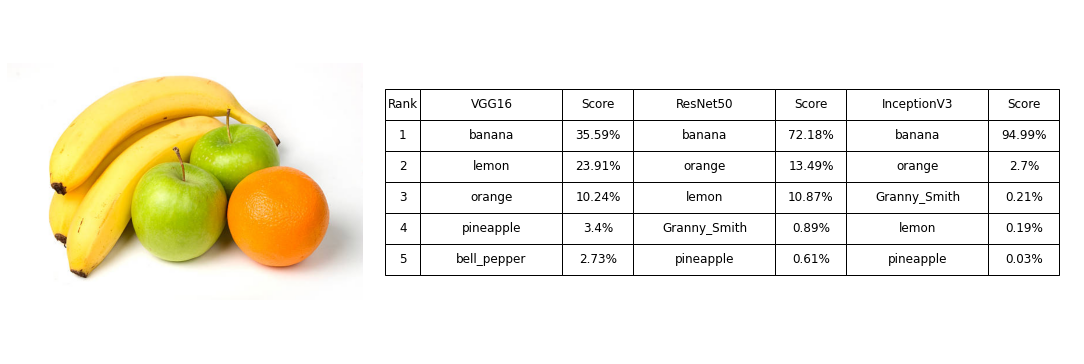

In [4]:
recognition(keras_models, model_vgg16, model_resnet50, model_inceptionv3, "test/frutas.jpg", K=5)

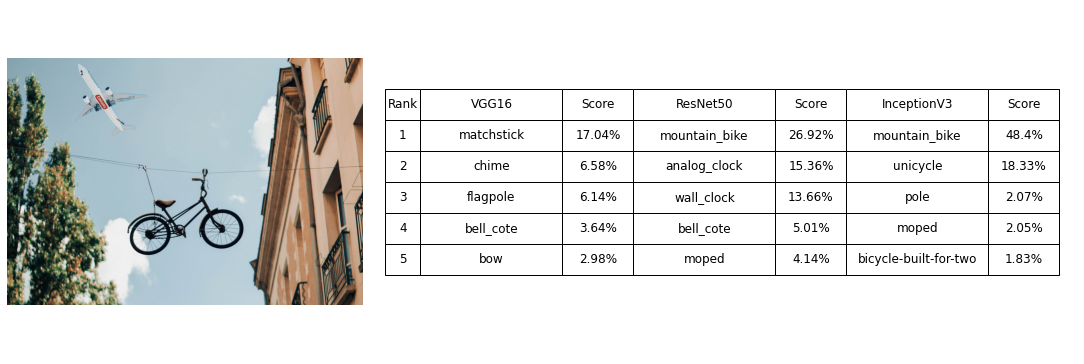

In [5]:
recognition(keras_models, model_vgg16, model_resnet50, model_inceptionv3, "test/AirplanewithBike.jpg", K=5)

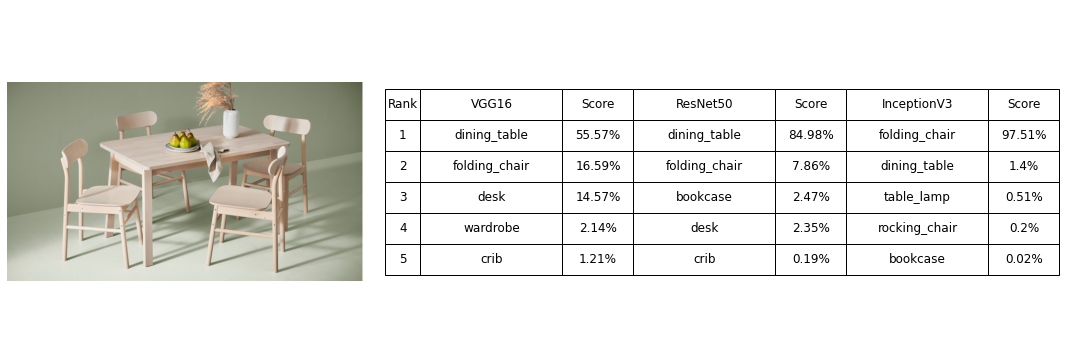

In [6]:
recognition(keras_models, model_vgg16, model_resnet50, model_inceptionv3, "test/dining.jpg", K=5)

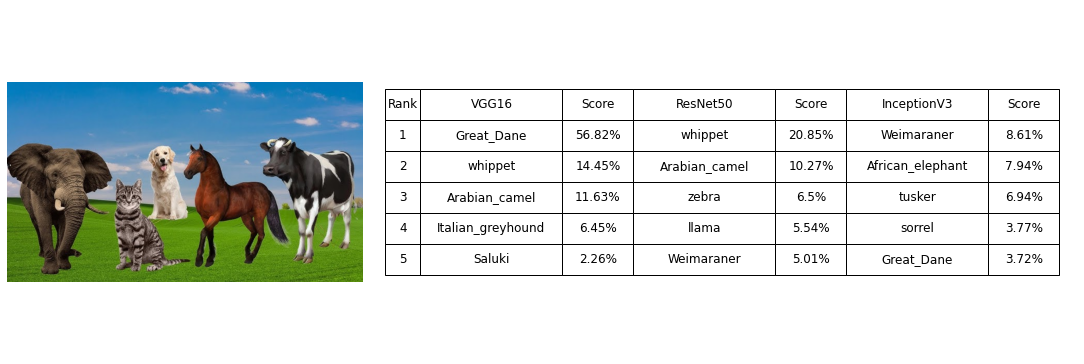

In [7]:
recognition(keras_models, model_vgg16, model_resnet50, model_inceptionv3, "test/animals.jpg", K=5)

# Semantic segmentation

Se centra en asignar una etiqueta a cada píxel de la imagen, lo que significa que se clasifica cada píxel en la imagen según la categoría a la que pertenece. El objetivo es entender la estructura y los contornos de los objetos en la imagen, lo que permite una comprensión detallada de la escena.

U-Net es conocida por su arquitectura de codificación-decodificación. FCN (Fully Convolutional Network) utiliza capas convolucionales completamente convolucionales. DeepLab emplea una estructura de atrás hacia adelante (decostructiva) para obtener segmentaciones precisas.

## DeepLab

Utiliza convoluciones atrous para capturar información contextual a diferentes escalas y el bloque Atrous Spatial Pyramid Pooling (ASPP) para obtener representaciones ricas en contexto. Esto permite una segmentación detallada y precisa de las imágenes.

<div align="center">
    <img src="img/Deeplabv3.png" alt="" width="60%" align="center" />
</div>

### Arquitectura DeepLab

DeepLabV3 utiliza la arquitectura Encoder-Decoder para capturar y procesar características a diferentes escalas y utiliza la convolución atrous o dilatada para capturar información contextual a diferentes escalas.

<div align="center">
    <img src="img/encoder_decoder.png" alt="" width="40%" align="left" />
    <img src="img/atrous_convolution.png" alt="" width="42%" align="left" />
</div>

### Atrous Spatial Pyramid Pooling (ASPP)

Utiliza convoluciones atrous a múltiples tasas de dilatación para capturar información contextual a diferentes escalas espaciales. Esto permite que la red tenga un conocimiento más completo y contextual de la imagen, lo que resulta en una segmentación más precisa y detallada.

<div align="center">
    <img src="img/ASPP.png" alt="" width="100%" align="center" />
</div>

## DeeplabV3

DeeplabV3 es una arquitectura de red neuronal convolucional diseñada para la segmentación semántica de imágenes, entrenado con 21 clases: *background, aeroplane, bicycle, bird, boat, bottle, bus, car, cat, chair, cow, diningtable, dog, horse, motorbike, person, pottedplant, sheep, sofa, train, tvmonitor*. Utiliza una serie de capas convolucionales profundas junto con atrous convolutions (convoluciones dilatadas) para capturar tanto información de contexto global como local en la imagen. 

In [8]:
deeplabv3_model = torch.hub.load('pytorch/vision:v0.10.0', 'deeplabv3_resnet50', force_reload=True, weights='DEFAULT')
deeplabv3_model = deeplabv3_model.eval()

Downloading: "https://github.com/pytorch/vision/zipball/v0.10.0" to /Users/nicolastorres/.cache/torch/hub/v0.10.0.zip


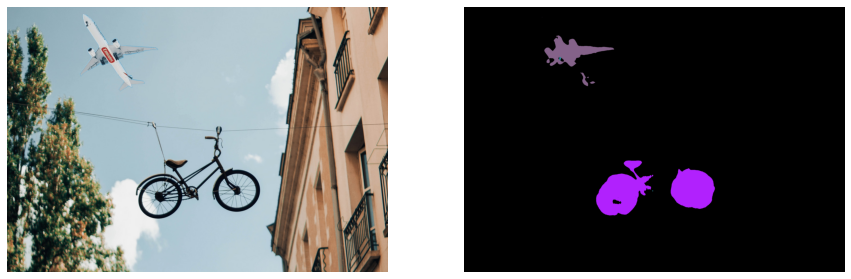

In [9]:
deeplab_segmentation(deeplabv3_model, "test/AirplanewithBike.jpg")

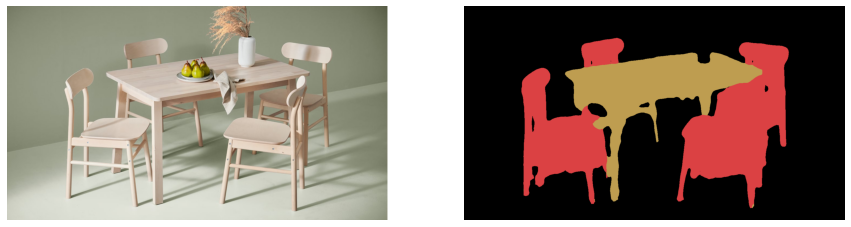

In [10]:
deeplab_segmentation(deeplabv3_model, "test/dining.jpg")

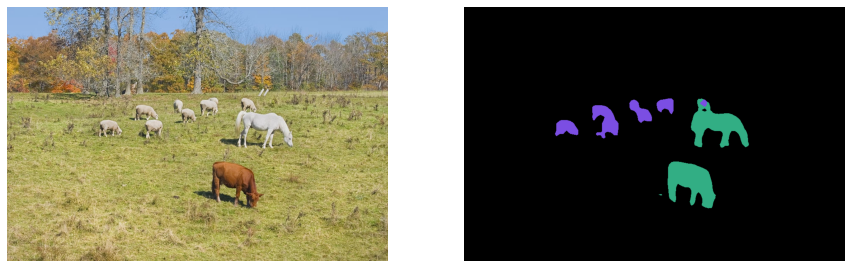

In [11]:
deeplab_segmentation(deeplabv3_model, "test/granja.jpg")

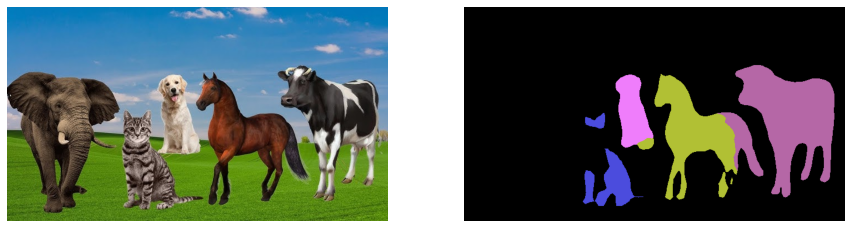

In [12]:
deeplab_segmentation(deeplabv3_model, "test/animals.jpg")

# Object detection

Consiste en identificar y localizar múltiples objetos dentro de una imagen. No solo se clasifican los objetos, sino que también se delimita su ubicación mediante cuadros delimitadores (bounding boxes). Esto permite detectar y etiquetar varios objetos diferentes en una sola imagen.

<div align="center">
    <img src="img/detection-bounding-box.jpeg" alt="" width="20%" align="center" />
</div>

Faster R-CNN usa dos etapas para detectar objetos, YOLO aborda el problema como una regresión directa y SSD (Single Shot Multibox Detector) combina diferentes escalas de detección.

## YOLO (You Only Look Once) 

YOLO divide la imagen en una cuadrícula, creando una malla que abarca toda la imagen. En lugar de trabajar con regiones propuestas, como otros métodos, YOLO analiza la imagen completa a través de esta cuadrícula.

<div align="center">
    <img src="img/grid.png" alt="" width="100%" align="center" />
</div>

## YOLO (You Only Look Once) 

Para cada celda de la cuadrícula, YOLO realiza múltiples predicciones. Cada predicción incluye un conjunto de cajas delimitadoras (bounding boxes) y las probabilidades de cada clase que podría contener la caja.

<div align="center">
    <img src="img/boxes.png" alt="" width="100%" align="center" />
</div>

## YOLO (You Only Look Once) 

Cada caja delimitadora tiene asociada una confianza y también las probabilidades de diferentes clases para ese objeto. Después de las predicciones, YOLO aplica un proceso llamado non-maximum suppression para eliminar las detecciones redundantes. Esto asegura que cada objeto se detecte solo una vez y se filtran las detecciones que se solapan significativamente.

<div align="center">
    <img src="img/non-max-suppression.jpeg" alt="" width="100%" align="center" />
</div>

In [13]:
yolov5 = torch.hub.load('ultralytics/yolov5', 'yolov5s', pretrained=True, verbose=False)

requirements: Ultralytics requirements ['gitpython>=3.1.30', 'Pillow>=10.0.1'] not found, attempting AutoUpdate...

requirements: AutoUpdate success ✅ 7.9s, installed 2 packages: ['gitpython>=3.1.30', 'Pillow>=10.0.1']
requirements: ⚠️ Restart runtime or rerun command for updates to take effect



YOLOv5 🚀 2023-11-16 Python-3.10.12 torch-2.1.0 CPU

Fusing layers... 
YOLOv5s summary: 213 layers, 7225885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


In [14]:
%matplotlib inline

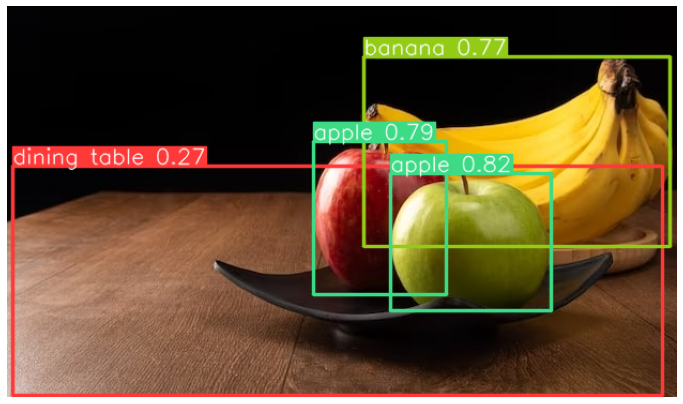

In [15]:
plot_result(model=yolov5, path="test/apples-banana.jpg")

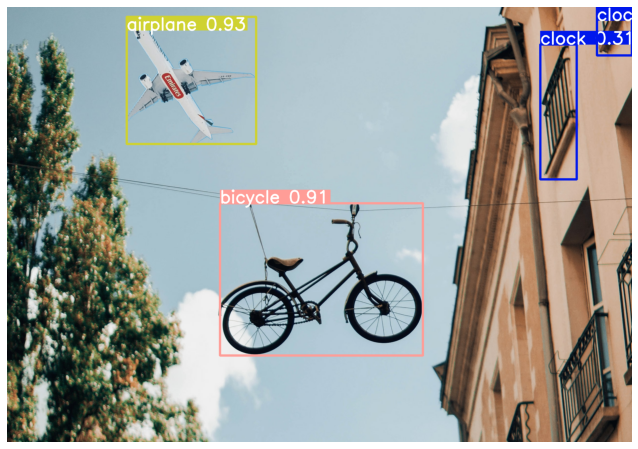

In [16]:
plot_result(model=yolov5, path="test/AirplanewithBike.jpg")

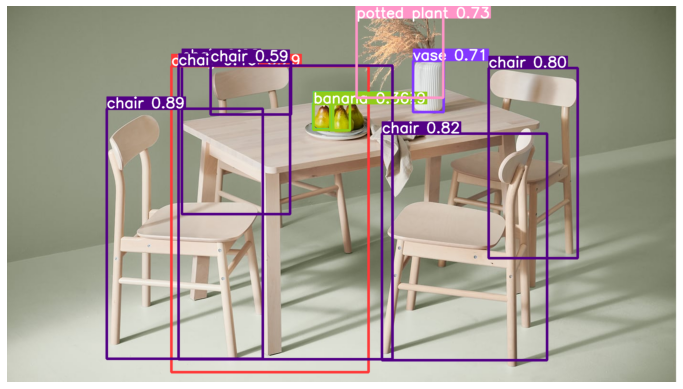

In [17]:
plot_result(model=yolov5, path="test/dining.jpg")

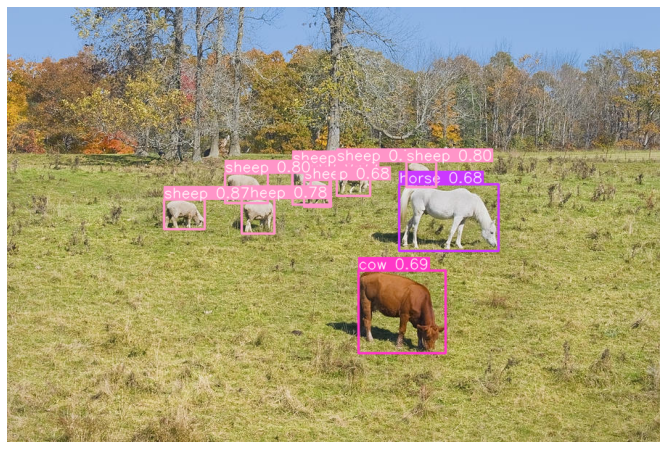

In [18]:
plot_result(model=yolov5, path="test/granja.jpg")

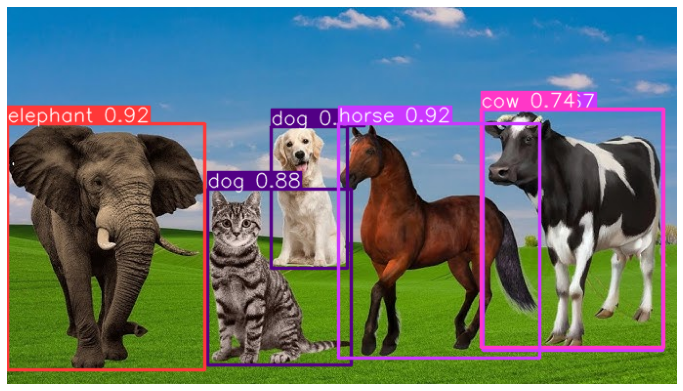

In [19]:
plot_result(model=yolov5, path="test/animals.jpg")

# Real-Time Detection with YOLO v8

In [6]:
real_time(video="webcam", task='detection', id_cam=1)

# YOLO-World

El YOLO-Modelo Mundial permite detección de vocabulario abierto.

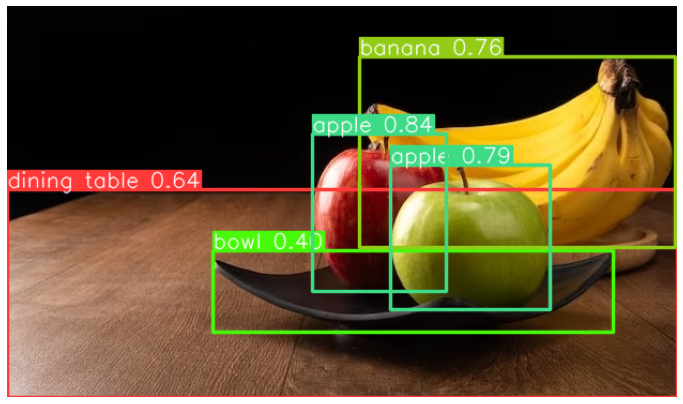

In [20]:
plot_yolo_world(path="test/apples-banana.jpg", classes=None)

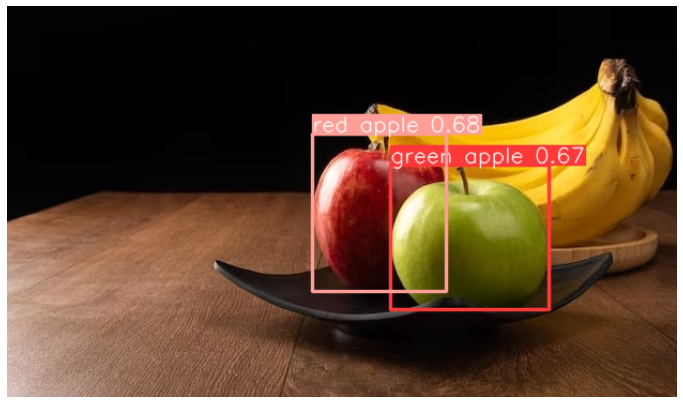

In [21]:
plot_yolo_world(path="test/apples-banana.jpg", classes=["green apple", "red apple"])

# Real-Time Detection with YOLO-World

In [5]:
real_time(video="webcam", task='world', id_cam=1, classes=["hand", "smartphone"])

## R-CNN

R-CNN (Region-based Convolutional Neural Network) utiliza regiones propuestas para identificar áreas de interés en una imagen. Extrae y clasifica estas regiones mediante una red convolucional, lo que permite detectar y delimitar objetos en la imagen, aunque su proceso es más lento debido al manejo individual de cada región propuesta.

<div align="center">
    <img src="img/RCNN.png" alt="" width="100%" align="center" />
</div>

## Fast R-CNN

Es una mejora de R-CNN que agiliza el proceso al introducir una red convolucional única para extraer características de la imagen completa en lugar de hacerlo para cada región propuesta individualmente. Luego, utiliza regiones de interés (RoIs) para extraer características específicas y aplicar clasificación y refinamiento, optimizando el tiempo de procesamiento y mejorando la precisión de la detección de objetos.

<div align="center">
    <img src="img/fast-RCNN.png" alt="" width="80%" align="center" />
</div>

## Faster R-CNN (RPN + Fast R-CNN)

La arquitectura Faster R-CNN consta de RPN como algoritmo de propuesta de región y Fast R-CNN como red de detectores.

<div align="center">
    <img src="img/Faster R-CNN.png" alt="" width="80%" align="center" />
</div>

# Instance segmentation

Similar a la detección de objetos, pero más avanzada, ya que no solo identifica y delimita la ubicación de los objetos, sino que también segmenta cada instancia individual de un objeto, proporcionando máscaras precisas que representan cada objeto encontrado en la imagen.

## Mask R-CNN

Mask R-CNN es una extensión de Faster R-CNN que agrega una rama adicional para realizar segmentación de instancias, proporcionando máscaras de píxeles precisas para cada objeto detectado. Combinando detección de objetos con segmentación a nivel de píxeles, Mask R-CNN permite identificar, localizar y segmentar objetos con gran precisión en imágenes.

<div align="center">
    <img src="img/mask-rcnn.png" alt="" width="60%" align="center" />
</div>

## MaskRCNN_ResNet50

Modelo de redes neuronales convolucionales que combina la detección de objetos con la segmentación de instancias, permitiendo identificar y delimitar los objetos en una imagen, así como generar máscaras de segmentación precisas para cada instancia detectada. Utiliza una arquitectura ResNet50 como extractor de características, lo que le permite alcanzar un equilibrio entre precisión y eficiencia computacional.

In [22]:
weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
maskrcnn_model = maskrcnn_resnet50_fpn(weights=weights, progress=False)
maskrcnn_model = maskrcnn_model.eval()

In [23]:
coco_names = ['__background__', 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus',
    'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'N/A', 'stop sign',
    'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow',
    'elephant', 'bear', 'zebra', 'giraffe', 'N/A', 'backpack', 'umbrella', 'N/A', 'N/A',
    'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball',
    'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket',
    'bottle', 'N/A', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl',
    'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza',
    'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'N/A', 'dining table',
    'N/A', 'N/A', 'toilet', 'N/A', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone',
    'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'N/A', 'book',
    'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush'
]

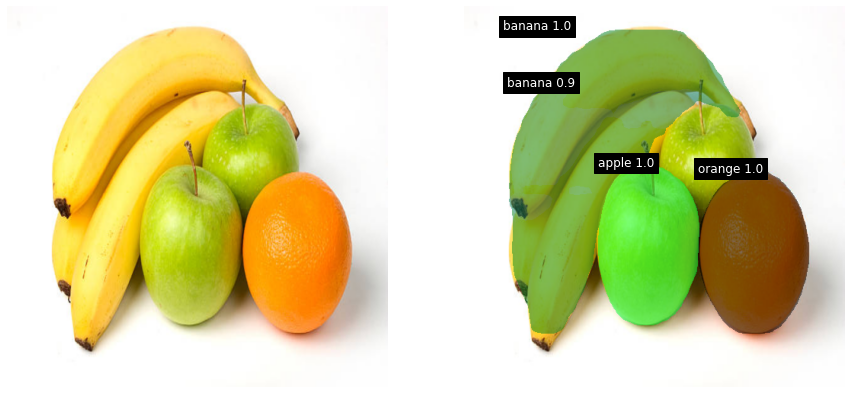

In [24]:
mask_segmentation(maskrcnn_model, weights, "test/frutas.jpg", coco_names)

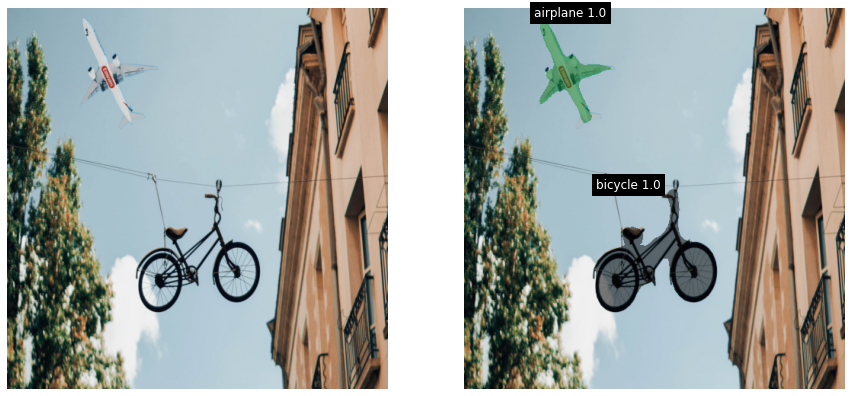

In [25]:
mask_segmentation(maskrcnn_model, weights, "test/AirplanewithBike.jpg", coco_names)

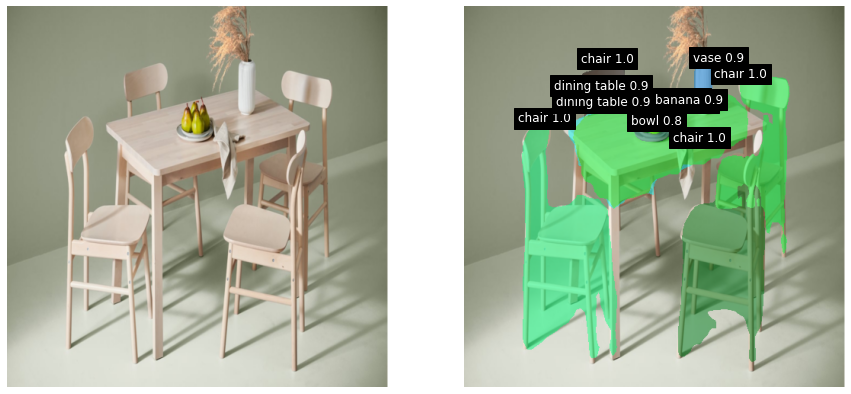

In [26]:
mask_segmentation(maskrcnn_model, weights, "test/dining.jpg", coco_names)

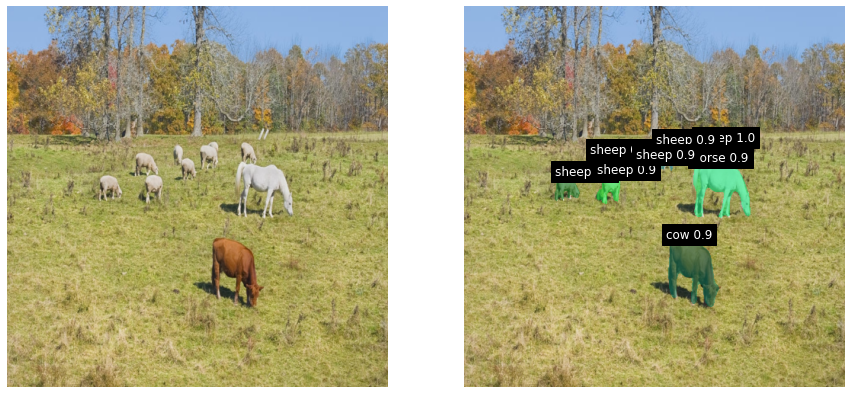

In [27]:
mask_segmentation(maskrcnn_model, weights, "test/granja.jpg", coco_names)

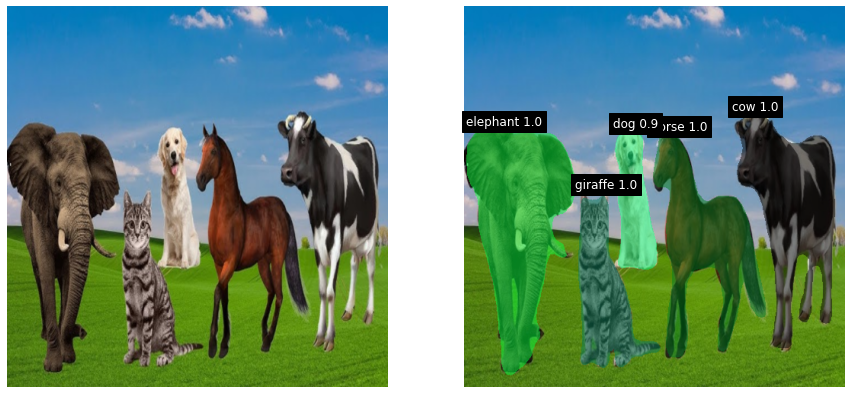

In [28]:
mask_segmentation(maskrcnn_model, weights, "test/animals.jpg", coco_names)

# Real-Time Segmentation with YOLO v8

In [7]:
real_time(video="webcam", task='segmentation', id_cam=1)